# Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
import copy as cp
import scipy.sparse.linalg as linalg
import matplotlib.pyplot as plt
from time import time
import scipy.optimize
import scipy.stats as stats
from mpl_toolkits.mplot3d import Axes3D
from scipy.spatial import KDTree

tf.get_logger().setLevel('ERROR')
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
  tf.config.experimental.set_memory_growth(gpu, True)

# Volumes finis

In [2]:
# Classe résolvant Burgers avec des volumes finis 1D (cours P. Helluy)
class EDP:
    def __init__(self,Nx,viscosity, u_0):
      
        self.Nx=Nx  # nb mailles
        self.a=-1.0  # bord gauche du domaine
        self.b=1.0  # bord droit du domaine
        self.viscosity = viscosity
        self.dt=0.0
        self.u_0 = u_0       

        # Pour le maillage Nx mailles et 2 maillages fantome a gauche et droite pour les conditions limites
        self.h=(self.b-self.a)/self.Nx  # pas de maillage
        self.begin = 1  # numéro de la première maille non fantome
        self.end=  self.Nx+1  # numéro de la dernière maille non fantome  
        
        self.nodes=np.linspace(self.a-self.h,self.b+self.h,self.Nx+3) 
        #listes des noeuds: n+1 noeuds et 2 noeuds fantomes
        self.cells=np.linspace(self.a-0.5*self.h,self.b+0.5*self.h,self.Nx+2)
        #listes des centres de mailles: n centres et 2 centres fantomes
        self.rho= np.zeros(self.Nx+2) ## rho sur le maillage + mailles fantomes
    
    #fonction pour initialiser rho
    def init(self):
    
        for i in range(0,len(self.rho)):
            self.rho[i]=self.u_0(self.cells[i])
    
        # on conserve le rho initiale
        self.rho_0=cp.copy(self.rho)

    # flux volumes finis de Lax-Friedrichs
    def flux_hyp_burgers(self,rl,rr):
        center = 0.5*(0.5*rl*rl+0.5*rr*rr)
        vel = max(abs(rl),abs(rr))
        visco=0.5*vel*(rl-rr)
        return center+visco
        
    # flux volumes finis du terme de diffusion
    def flux_diff(self,rl,rr):
        grad = self.viscosity*(rr-rl)/self.h
        return grad
    
    # plot de rho_0 et de rho
    def plot(self):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].plot(self.cells[self.begin:self.end],self.rho_0[self.begin:self.end],'r-')
        axes[1].plot(self.cells[self.begin:self.end],self.rho[self.begin:self.end],'b-')
        
    # condition limite dans les mailles fantomes selon le cas test. A expliquer
    def bc(self):
        self.rho[0]=0
        self.rho[-1]=0
    
    # le terme de diffusion est traité par un schéma implicite en temps
    # le terme de Burgers par un schema implicite
    # Ici on contruit le produit matrice vecteur entre la matrice implicite et un vecteur v
    def matvec_Laplacian(self,v):
        res=np.zeros(self.Nx)
        vl=0.0
        vr=0.0

        res[0]= v[0]-self.dt*self.viscosity/(self.h**2.0)*(vl-2.0*v[0]+v[1])
        for i in range(1,self.Nx-1):
            res[i]= v[i]-self.dt*self.viscosity/(self.h**2.0)*(v[i-1]-2.0*v[i]+v[i+1])
            
        res[-1]= v[-1]-self.dt*self.viscosity/(self.h**2.0)*(v[-2]-2.0*v[-1]+vr)
        return res
        
    # Résolution de l'équation en temps
    # A est un opérateur linéaire associée à la matrice implicite (le produit matrice vecteur)
    # on a pas besoin de construire la matrice pour résoudre un problème avec le gradient conjugé.
    # Il suffit juste de donner ce produit matrice vecteur
    def solve_loc(self,T,flux):
        sol=[]
        nt = 0
        time = 0.0
        rho_temp = np.zeros(self.Nx)
        self.A = linalg.LinearOperator((self.Nx,self.Nx), matvec=self.matvec_Laplacian)
        while time < T:
            # vitesse max de l'équation utile pour CFL
            vmax=max(abs(self.rho[self.begin:self.end]))
            self.dt= 0.5*self.h/vmax
            for i in range(0,self.Nx):
                # calcul des conditions limites dans la mailles fantomes
                self.bc()
                rhol = self.rho[self.begin+i-1]
                rhoc = self.rho[self.begin+i]
                rhor = self.rho[self.begin+i+1]
                # calcul des flux explicite
                fh=flux(rhoc,rhor)-flux(rhol,rhoc)
                # schéma en temps explicite
                rho_temp[i]=rhoc -self.dt/self.h*fh
        
            # schéma en temps implicite en résovlant Arho^{n+1}= Explicit
            self.rho[self.begin:self.end],info=linalg.cg(self.A,rho_temp,x0=None,tol=1e-06,maxiter=200)
            sol.append(cp.copy(self.rho[self.begin:self.end]))
            time=time+self.dt
            nt=nt+1
        return sol
    
    def solve(self,T):
        sol=self.solve_loc(T,self.flux_hyp_burgers)
        return sol

def u_0(x):
  return -np.sin(np.pi*x)

# Paramètres du problème

par rapport aux PINN classique on a rajouté une dimension aux variables qui correspond à la viscosité

In [3]:
# Set data type
DTYPE='float32'
tf.keras.backend.set_floatx(DTYPE)

# Set constants
pi = tf.constant(np.pi, dtype=DTYPE)

# Set boundary
tmin = 0.
tmax = 1.
xmin = -1.
xmax = 1.

numin = 1e-4
numax=  1e-2

# Lower bounds
lb = tf.constant([tmin, xmin, numin], dtype=DTYPE)
# Upper bounds
ub = tf.constant([tmax, xmax, numax], dtype=DTYPE)

# Define initial condition
def fun_u_0(x):
    return -tf.sin(pi * x)

# Define boundary condition
def fun_u_b(t, x):
    n = x.shape[0]
    return tf.zeros((n,1), dtype=DTYPE)

# données d'entrainement

In [4]:
def gen_train_data(N_r=10_000):

  # Set random seed for reproducible results
  tf.random.set_seed(0)

  # Draw uniformly sampled collocation points
  t_r = tf.random.uniform((N_r,1), lb[0], ub[0], dtype=DTYPE)
  x_r = tf.random.uniform((N_r,1), lb[1], ub[1], dtype=DTYPE)
  nu_r = tf.random.uniform((N_r,1), lb[2], ub[2], dtype=DTYPE)
  X_r = tf.concat([t_r, x_r, nu_r], axis=1)

  return X_r

# residu/entropie

In [5]:
def get_residual(model, X_r):
    """fonction qui calcule le résidu"""
    
    # Split t and x to compute partial derivatives
    t, x = X_r[:, 0:1], X_r[:,1:2]
    nu = X[:,2:3]
        
    with tf.GradientTape(persistent=True) as tape:
        # Watch variables representing t and x during this GradientTape
        tape.watch(t)
        tape.watch(x)

        # Compute current values u(t,x) and u(t,x)^2
        u = model(tf.stack([t[:,0], x[:,0]], axis=1))
        u2 = tf.square(u)

        u_x = tape.gradient(u, x)

    u_t = tape.gradient(u, t)
    u_xx = tape.gradient(u_x, x)
    u2_x = tape.gradient(u2, x)

    del tape

    return u_t + u2_x/2. - nu * u_xx

def get_entropy(model, X_r):
    """fonction qui calcule l'entropie """
    
    with tf.GradientTape(persistent=True) as tape:
        # Split t and x to compute partial derivatives
        t, x = X_r[:, 0:1], X_r[:,1:2]
        nu = X[:,2:3]

        # Variables t and x are watched during tape
        # to compute derivatives u_t and u_x
        tape.watch(t)
        tape.watch(x)
        
        u = model(tf.stack([t[:,0], x[:,0]], axis=1))
        u2 = tf.square(u)
        u3 = u*u2

        # Compute gradient u_x within the GradientTape
        # since we need second derivatives
        u2_x = tape.gradient(u2, x)
            
    eta_t = tape.gradient(u2, t)
    q_x = tape.gradient(u3, x)
    eta_xx = tape.gradient(u2_x, x)

    del tape

    return eta_t/2 +  q_x/3 - nu * eta_xx

## PINN model

In [6]:
class PhysicsInformedNN(tf.keras.Model):
    """ Set basic architecture of the PINN model."""

    def __init__(self, lb, ub, 
            output_dim=1,
            num_hidden_layers=8, 
            num_neurons_per_layer=20,
            activation='tanh',
            kernel_initializer='glorot_normal',
            **kwargs):
        super().__init__(**kwargs)

        self.num_hidden_layers = num_hidden_layers
        self.output_dim = output_dim
        self.lb = lb
        self.ub = ub
        
        # Define NN architecture
        self.scale = tf.keras.layers.Lambda(
            lambda x: 2.0*(x - lb)/(ub - lb) - 1.0)
        self.hidden = [tf.keras.layers.Dense(num_neurons_per_layer,
                             activation=tf.keras.activations.get(activation),
                             kernel_initializer=kernel_initializer)
                           for _ in range(self.num_hidden_layers)]
        self.out = tf.keras.layers.Dense(output_dim)

    def call_before(self,X):
        """Forward-pass through neural network."""
        
        Z = self.scale(X)
        for i in range(self.num_hidden_layers):
            Z = self.hidden[i](Z)
        Y = self.out(Z)
        
        return Y
        
        
    def call(self, X):
        """Call with imposed IC/BC"""
        
        # passage dans le NN
        Y = self.call_before(X)

        # imposer conditions au bords
        t, x = X[:,0:1], X[:,1:2]
        tanh_t = tf.tanh(t)
    
        return (1-tanh_t)*fun_u_0(x) + (x+1)*(1-x)*tanh_t*Y

In [7]:
class PINNSolver():
    def __init__(self, model, batch_size):
        self.model = model
        
        # Initialize history of losses and global iteration counter
        self.hist = []
        self.epoch = 0
        self.batch_size = batch_size
        self.best_loss = 1.0
        self.count_since_best_loss = 0
    
    def get_r(self, X):
        
        t = X[:,0:1]
        x = X[:,1:2]
        nu = X[:,2:3]
        
        with tf.GradientTape(persistent=True) as tape:
            # Watch variables representing t and x during this GradientTape
            tape.watch(t)
            tape.watch(x)
        
            # Compute current values u(t,x)
            u = self.model(tf.stack([t[:,0], x[:,0], nu[:,0]], axis=1))
            u2 = tf.square(u)
            
            u_x = tape.gradient(u, x)
            
        u_t = tape.gradient(u, t)
        u_xx = tape.gradient(u_x, x)
        u2_x = tape.gradient(u2, x)

        
        del tape
        
        return u_t + u2_x/2. - nu * u_xx
    
    def loss_fn(self, X):
        
        # Compute phi_r
        r = self.get_r(X)
        phi_r = tf.reduce_mean(tf.square(r))
        
        # Initialize loss
        loss = phi_r
        return loss
    
    def get_grad(self, X):
        with tf.GradientTape(persistent=True) as tape:
            # This tape is for derivatives with
            # respect to trainable variables
            tape.watch(self.model.trainable_variables)
            loss = self.loss_fn(X)
            
        g = tape.gradient(loss, self.model.trainable_variables)
        del tape
        
        return loss, g
    

    def solve_with_TFoptimizer(self, optimizer, X_r, alpha):
        """This method performs a gradient descent type optimization."""
        
        self.nb_uniform  = int(alpha * self.batch_size)
        self.nb_residual = int((1-alpha) * self.batch_size)
        
        @tf.function
        def train_step(batch):
            loss, grad_theta = self.get_grad(batch)
            
            # Perform gradient descent step
            optimizer.apply_gradients(zip(grad_theta, self.model.trainable_variables))
            return loss
        
        num_epochs = 60_000
        for epoch in range(num_epochs):
                        
        # calcul de q_i 
          J_rho = self.get_r(X_r) 
          sum_J_rho = tf.reduce_sum(J_rho**2)
          q = J_rho**2 / sum_J_rho
          q = q.numpy().flatten()
        
          for step in range(1):

              # tire les points 
              indices_uniform  = np.random.choice(len(X_r), size=self.nb_uniform, replace=False)
              indices_residual = np.random.choice(len(X_r), size=self.nb_residual, replace=False, p=q)
              indices = np.concatenate((indices_uniform, indices_residual), axis=None)
              self.batch = tf.gather(X_r, indices)

              # descente de gradient
              loss = train_step(self.batch)

          self.current_loss = self.loss_fn(X_r)
          self.callback()
            
        self.model.load_weights('best_weight_residu.h5')
        print('\nBest loss = {:10.8e}'.format(self.best_loss))
        
    def solve_with_ScipyOptimizer(self, X, method='L-BFGS-B'):
        
        def get_weight_tensor():
            """Function to return current variables of the model
            as 1d tensor as well as corresponding shapes as lists."""
            
            weight_list = []
            shape_list = []
            
            # Loop over all variables, i.e. weight matrices, bias vectors and unknown parameters
            for v in self.model.variables:
                shape_list.append(v.shape)
                weight_list.extend(v.numpy().flatten())
                
            weight_list = tf.convert_to_tensor(weight_list)
            return weight_list, shape_list

        x0, shape_list = get_weight_tensor()
        
        def set_weight_tensor(weight_list):
            """Function which sets list of weights
            to variables in the model."""
            idx = 0
            for v in self.model.variables:
                vs = v.shape
                
                # Weight matrices
                if len(vs) == 2:  
                    sw = vs[0]*vs[1]
                    new_val = tf.reshape(weight_list[idx:idx+sw],(vs[0],vs[1]))
                    idx += sw
                
                # Bias vectors
                elif len(vs) == 1:
                    new_val = weight_list[idx:idx+vs[0]]
                    idx += vs[0]
                    
                # Variables (in case of parameter identification setting)
                elif len(vs) == 0:
                    new_val = weight_list[idx]
                    idx += 1
                    
                # Assign variables (Casting necessary since scipy requires float64 type)
                v.assign(tf.cast(new_val, DTYPE))
        
        def get_loss_and_grad(w):
            """Function that provides current loss and gradient
            w.r.t the trainable variables as vector. This is mandatory
            for the LBFGS minimizer from scipy."""
            
            # Update weights in model
            set_weight_tensor(w)
            # Determine value of \phi and gradient w.r.t. \theta at w
            loss, grad = self.get_grad(X)
            
            # Store current loss for callback function            
            loss = loss.numpy().astype(np.float64)
            self.current_loss = loss            
            
            # Flatten gradient
            grad_flat = []
            for g in grad:
                grad_flat.extend(g.numpy().flatten())
            
            # Gradient list to array
            grad_flat = np.array(grad_flat,dtype=np.float64)
            
            # Return value and gradient of \phi as tuple
            return loss, grad_flat
        
        
        return scipy.optimize.minimize(fun=get_loss_and_grad,
                                       x0=x0,
                                       jac=True,
                                       method=method,
                                       callback=self.callback,
                                       options={'maxiter': 3000,
                                                'maxfun': 50000,
                                                'maxcor': 50,
                                                'maxls': 50,
                                                'ftol': 1.0*np.finfo(float).eps})

    def callback(self, xr=None):
        self.count_since_best_loss+=1
        
        if self.epoch % 100 == 0:
            print('\rEpoch {:06_}: loss = {:10.8e}'.format(self.epoch,self.current_loss), end='')
            
            if self.current_loss < self.best_loss:
                self.best_loss = self.current_loss
                self.count_since_best_loss = 0
                self.model.save_weights('best_weight_residu.h5')
                
            if self.count_since_best_loss == 2000:
                self.model.load_weights('best_weight_residu.h5')
                
        if self.epoch % 10_000 == 0:
            self.plot_distribution()
                
        self.hist.append(self.current_loss)
        self.epoch+=1
        
    def plot_loss_history(self, ax=None):

        if not ax:
            fig = plt.figure(figsize=(7,5))
            ax = fig.add_subplot(111)

        ax.semilogy(range(len(self.hist)), self.hist,'k-', label='Loss')
        ax.set_xlabel('$Iteration$')
        ax.set_ylabel('Loss')

        return ax
    
    def plot_distribution(self, ax=None):
        
        if not ax:
            fig = plt.figure(figsize=(7,5))
            ax = fig.add_subplot(111)

        nus = self.batch[:,2:3].numpy()
        ax.plot(nus, np.ones_like(nus),'b+')
        ax.set_xlabel('viscosity')
        ax.set_title('viscosity distribution at epoch {}'.format(self.epoch))

        return ax

# Entrainements avec 30 000 points

In [8]:
X_r = gen_train_data(30_000)

N_val = 20_000
tspace = np.linspace(tmin,tmax,N_val)
xspace = np.linspace(xmin,xmax,N_val)
nuspace = np.linspace(numin,numax,N_val)

X_val = np.vstack([tspace.flatten(), xspace.flatten(), nuspace.flatten()]).T
X_val = tf.cast(X_val,DTYPE)

Epoch 59_900: loss = 2.03912223e-05
Best loss = 2.03912223e-05

Training time: 8941.472355365753 seconds


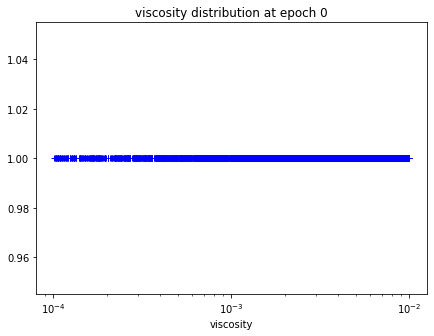

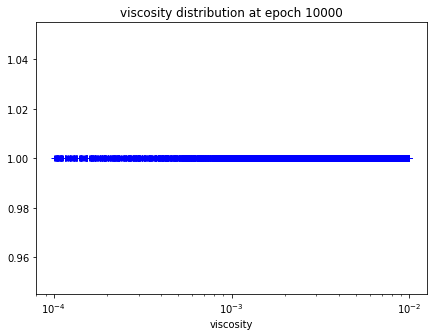

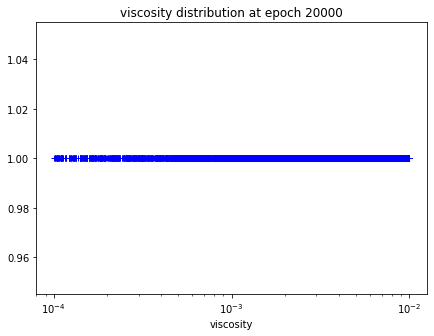

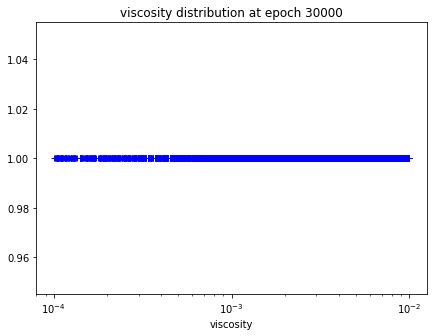

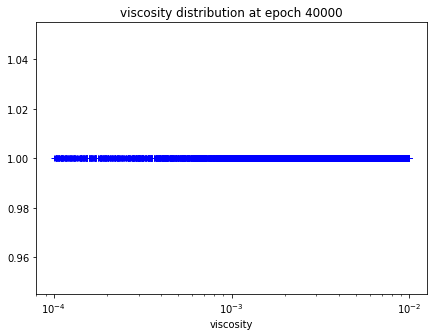

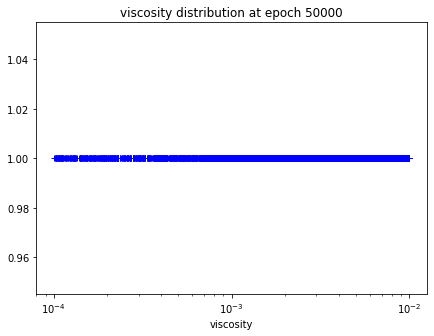

In [9]:
model = PhysicsInformedNN(lb, ub, num_hidden_layers=10, num_neurons_per_layer=150, activation='tanh')
solver = PINNSolver(model, batch_size = 10_000)

t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-3,
    decay_steps=200,
    decay_rate=0.97,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, X_r, alpha = 0.2)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Epoch 61_900: loss = 7.74252112e-06
Training time: 689.0162973403931 seconds


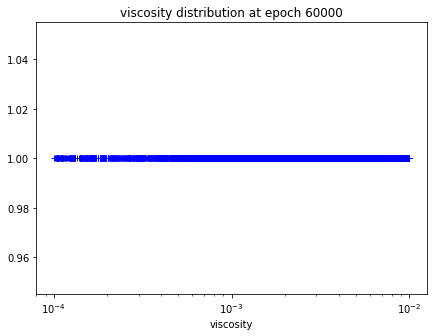

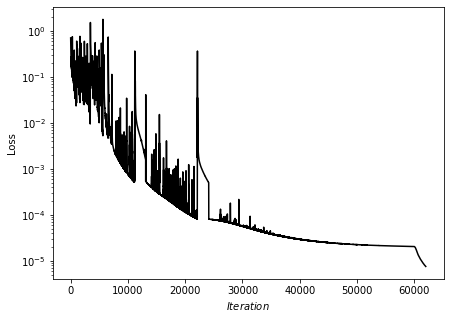

In [10]:
#model.load_weights('best_weight.h5')

t0 = time()
try: 
  solver.solve_with_ScipyOptimizer(X_r)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

solver.plot_loss_history();

## vérification que ca fonctionne 

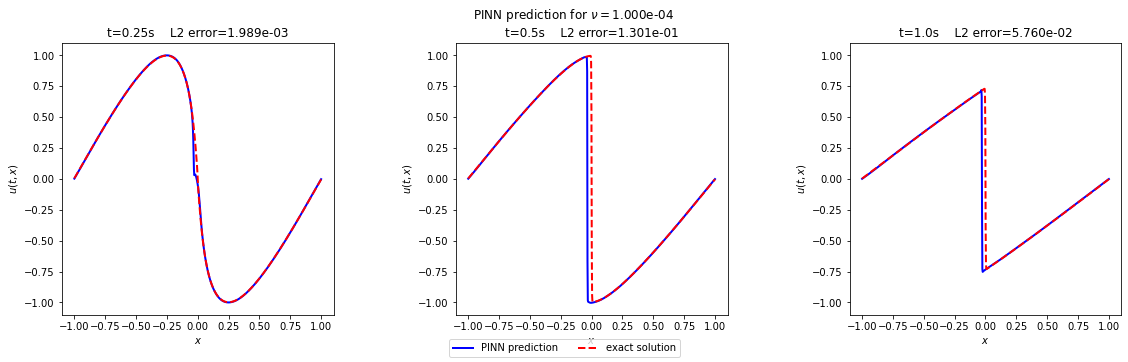

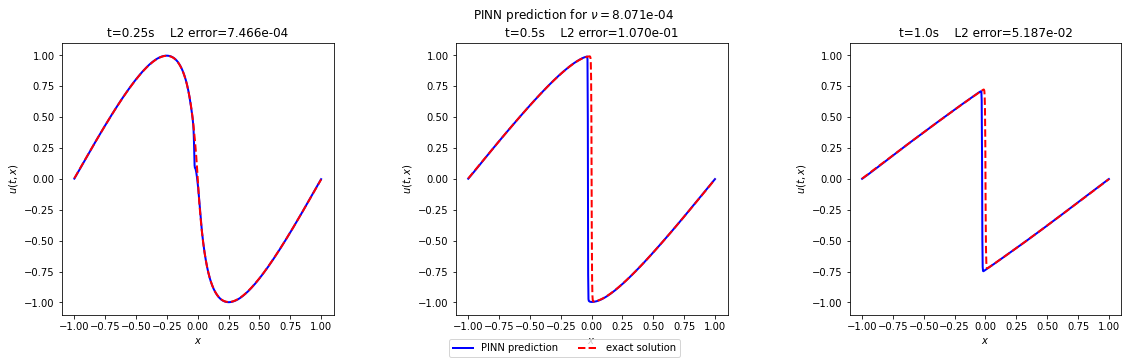

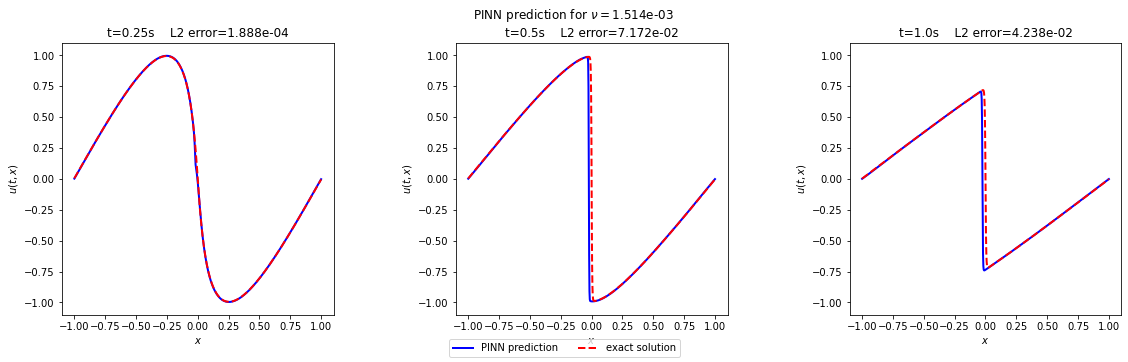

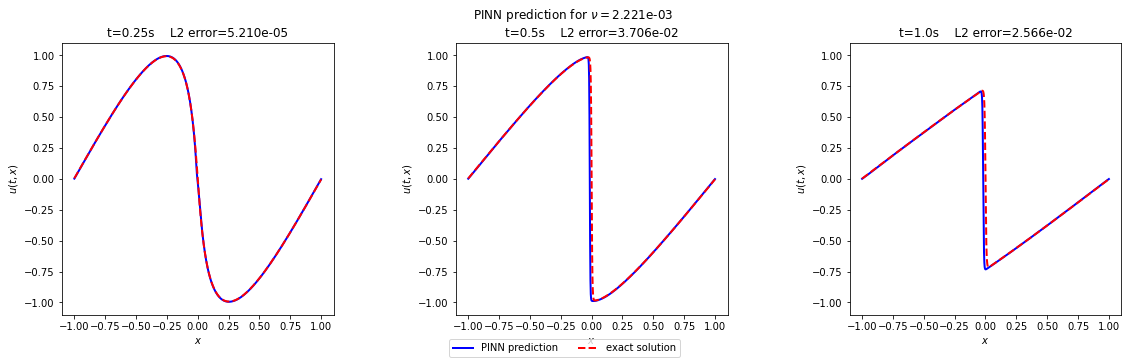

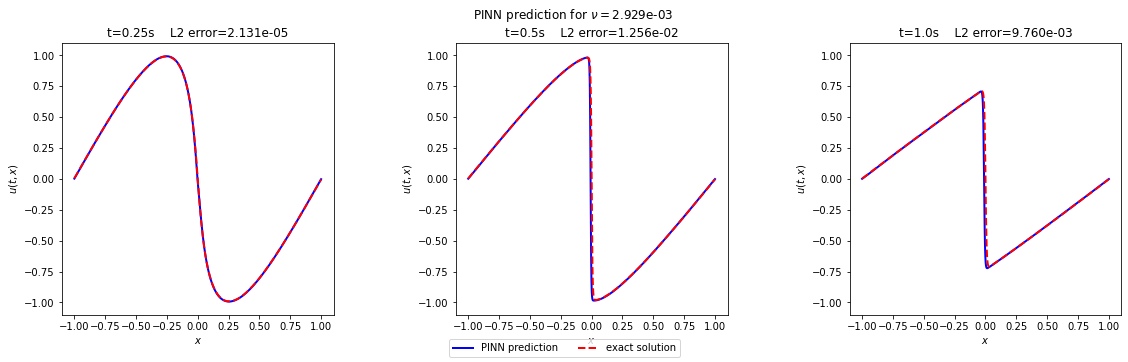

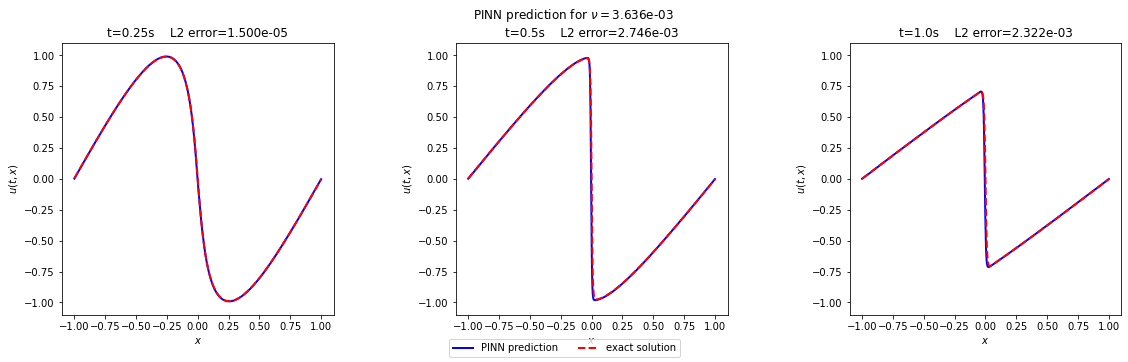

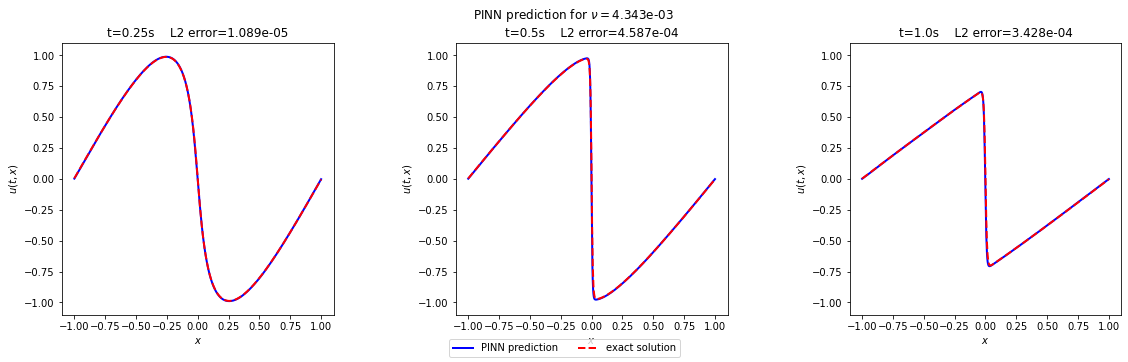

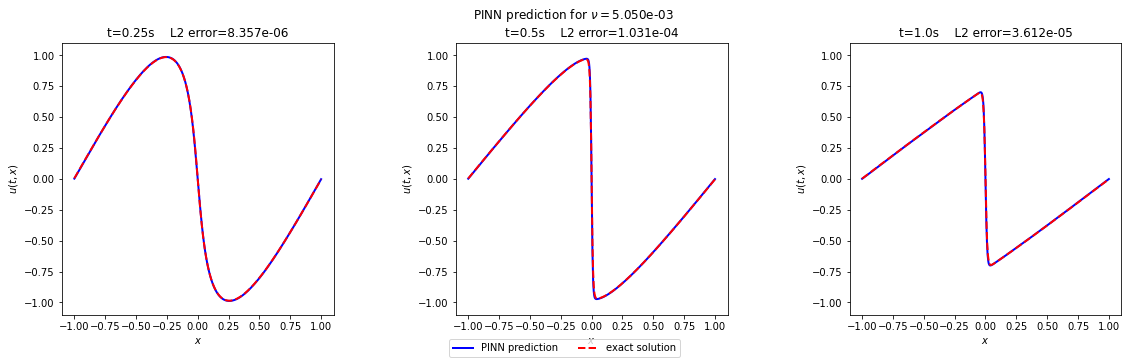

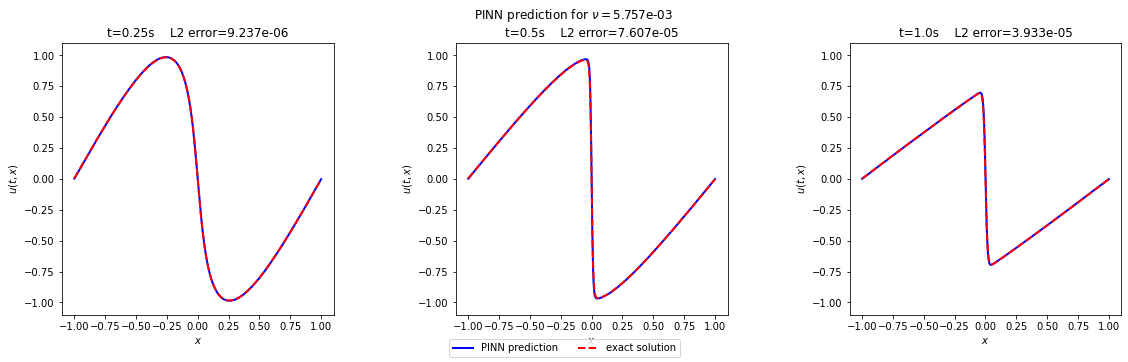

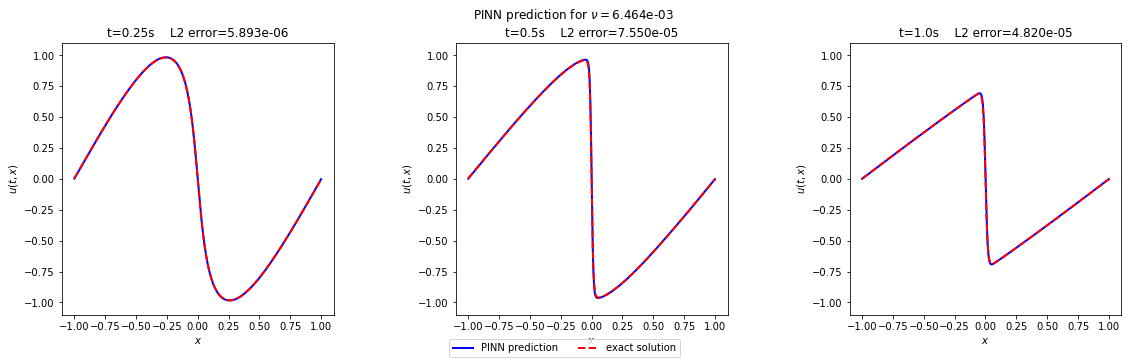

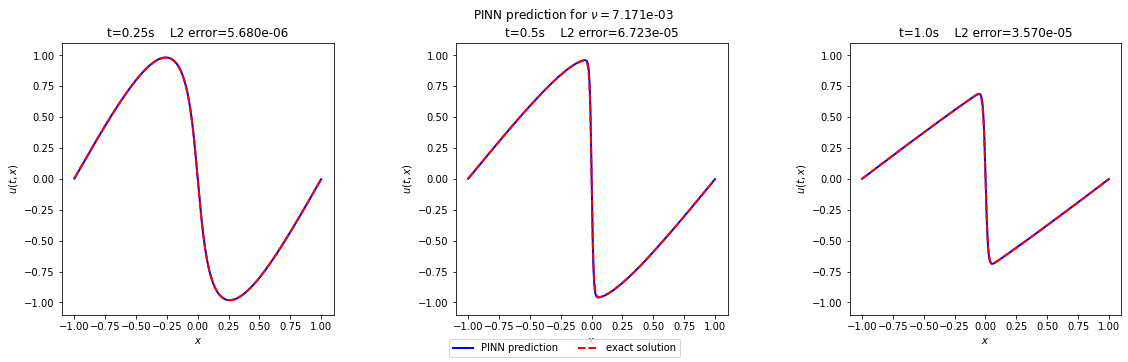

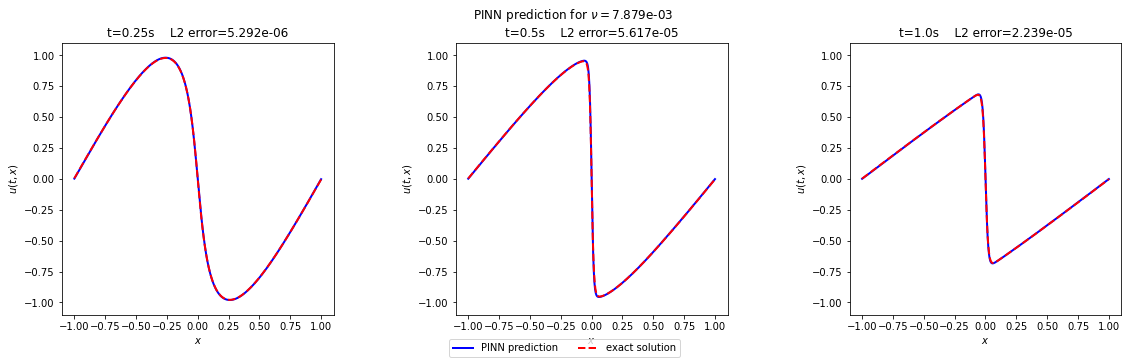

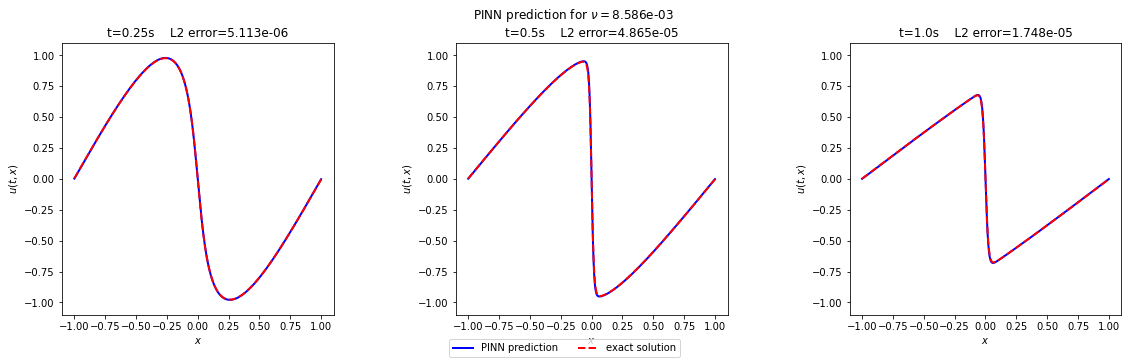

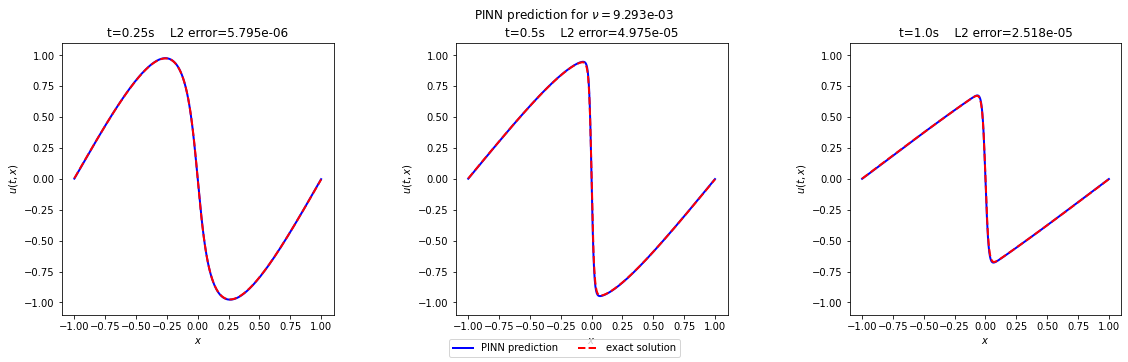

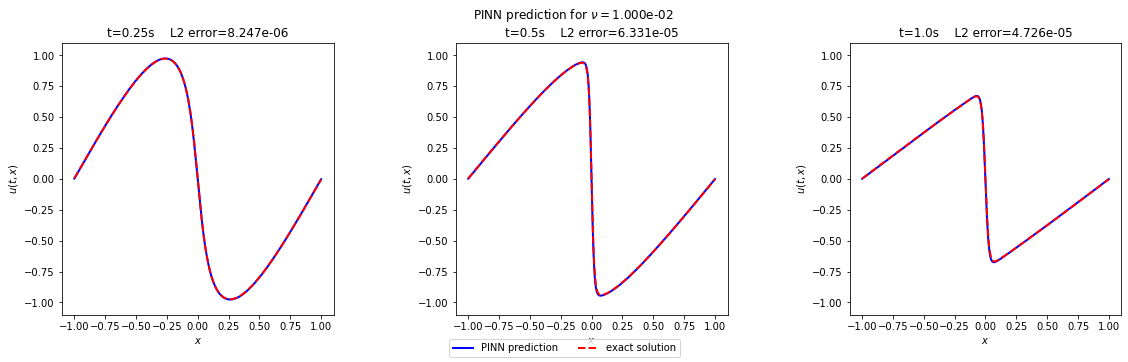

In [11]:
N = 750

for visc in np.linspace(numin, numax, 15):
    
  bg=EDP(N, visc, u_0)
  x = bg.cells[bg.begin:bg.end]

  fig, ax = plt.subplots(1, 3, figsize=(20, 5))

  all_times = [0.25, 0.5, 1.0]
  for i_t, end_time in enumerate(all_times):
    
      bg.init()
      sol=bg.solve(end_time)
      exact_sol = sol[-1]

      # solution en utilisant le PINN
      T, X = np.meshgrid(end_time, x)
      nuspace = visc * np.ones(N)
      Xgrid = np.vstack([T.flatten(),x.flatten(), nuspace.flatten()]).T
      upred = model(tf.cast(Xgrid,DTYPE))
      upred = tf.reshape(upred, (1,N))[0].numpy()

      # affichage
      erreurL2 = (x[-1]-x[0])/N*np.sum((exact_sol-upred)**2)
      title = "t={}s    L2 error={:5.3e}".format(end_time, erreurL2)
      ax[i_t].set_title(title)

      ax[i_t].plot(x, upred, 'b-', linewidth = 2, label="PINN prediction")
      ax[i_t].plot(x, exact_sol, 'r--', linewidth = 2, label="exact solution")

      ax[i_t].set_xlabel('$x$')
      ax[i_t].set_ylabel('$u(t,x)$')    
      ax[i_t].axis('square')
      ax[i_t].set_xlim([-1.1,1.1])
      ax[i_t].set_ylim([-1.1,1.1]);

  handles, labels = ax[-1].get_legend_handles_labels()
  fig.legend(handles, labels, loc='lower center', ncol=4);
  plt.suptitle(r"PINN prediction for $\nu=${:5.3e}".format(visc))

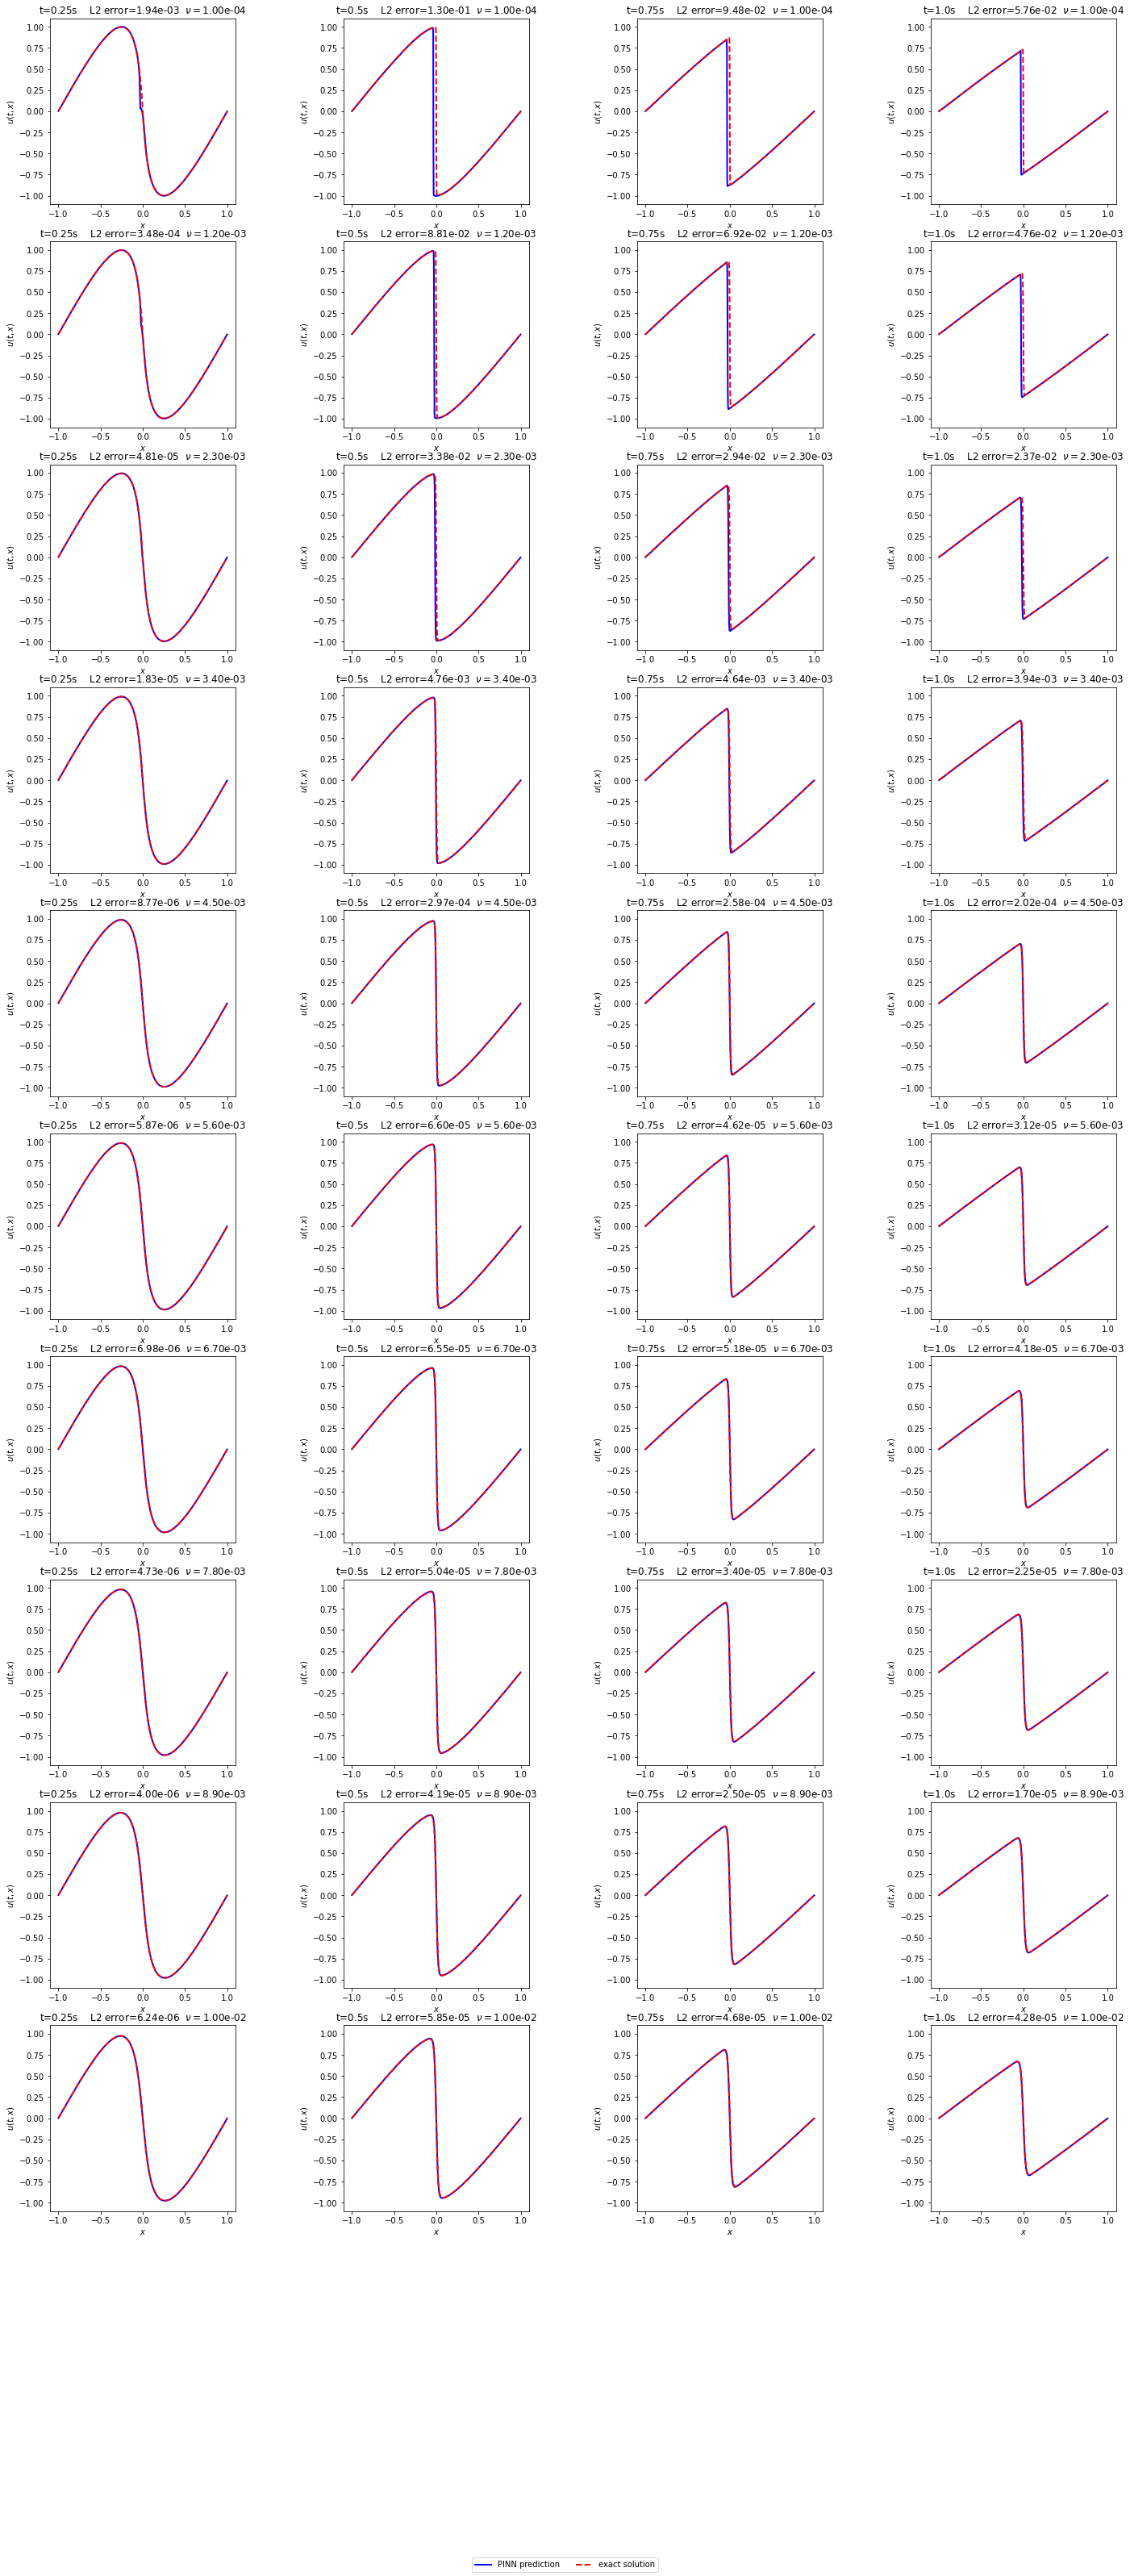

In [12]:
N = 800
M = 10

fig, ax = plt.subplots(M, 4, figsize=(25, 5*M))

for j, visc in enumerate(np.linspace(numin, numax, M)):
    
  bg=EDP(N, visc, u_0)
  x = bg.cells[bg.begin:bg.end]

  all_times = [0.25, 0.5, 0.75, 1.0]
  for i_t, end_time in enumerate(all_times):
    
      bg.init()
      sol=bg.solve(end_time)
      exact_sol = sol[-1]

      # solution en utilisant le PINN
      T, X = np.meshgrid(end_time, x)
      nuspace = visc * np.ones(N)
      Xgrid = np.vstack([T.flatten(),x.flatten(), nuspace.flatten()]).T
      upred = model(tf.cast(Xgrid,DTYPE))
      upred = tf.reshape(upred, (1,N))[0].numpy()

      # affichage
      erreurL2 = (x[-1]-x[0])/N*np.sum((exact_sol-upred)**2)
      title = r"t={}s    L2 error={:4.2e}  $\nu=${:4.2e}".format(end_time, erreurL2, visc)
      ax[j][i_t].set_title(title)

      ax[j][i_t].plot(x, upred, 'b-', linewidth = 2, label="PINN prediction")
      ax[j][i_t].plot(x, exact_sol, 'r--', linewidth = 2, label="exact solution")

      ax[j][i_t].set_xlabel('$x$')
      ax[j][i_t].set_ylabel('$u(t,x)$')    
      ax[j][i_t].axis('square')
      ax[j][i_t].set_xlim([-1.1,1.1])
      ax[j][i_t].set_ylim([-1.1,1.1]);

handles, labels = ax[-1][-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4);

# Entrainement avec 60 000 points

In [13]:
X_r = gen_train_data(60_000)

Epoch 59_900: loss = 3.46900051e-05
Best loss = 3.46900051e-05

Training time: 22187.819231987 seconds


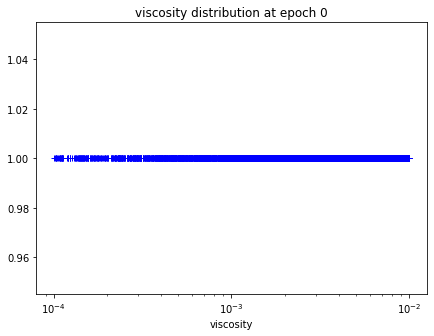

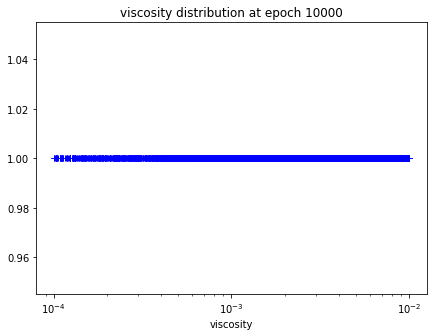

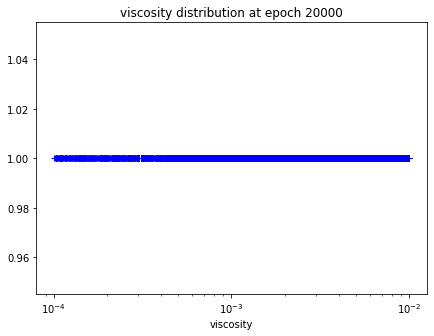

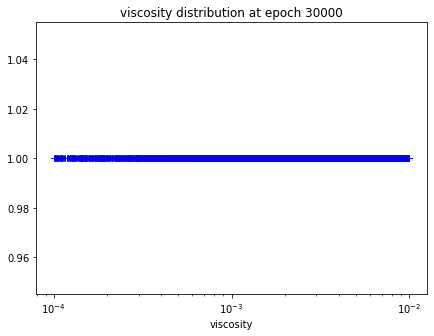

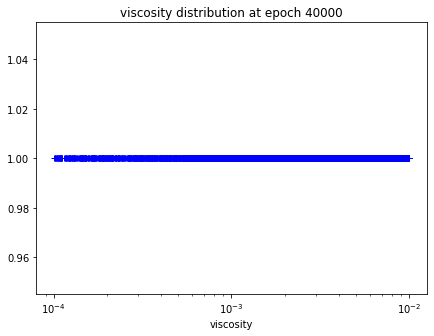

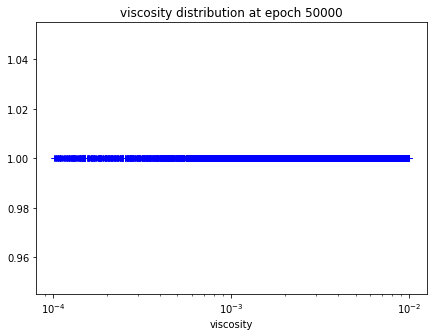

In [14]:
model = PhysicsInformedNN(lb, ub, num_hidden_layers=10, num_neurons_per_layer=150, activation='tanh')
solver = PINNSolver(model, batch_size = 10_000)

t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-3,
    decay_steps=200,
    decay_rate=0.97,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, X_r, alpha = 0.2)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Epoch 61_900: loss = 8.14247960e-06
Training time: 1320.5707483291626 seconds


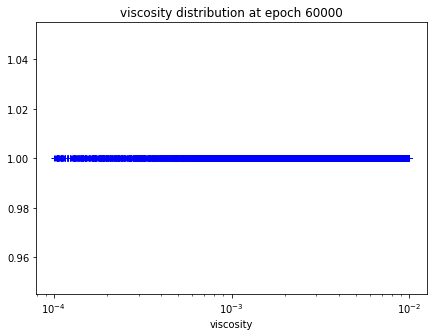

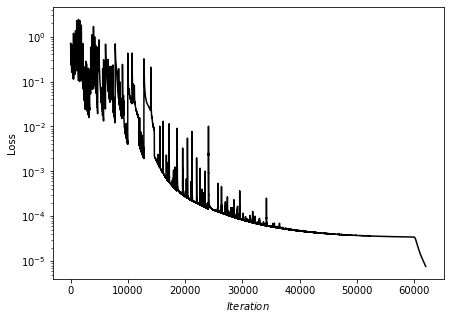

In [15]:
#model.load_weights('best_weight.h5')

t0 = time()
try: 
  solver.solve_with_ScipyOptimizer(X_r)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

solver.plot_loss_history();

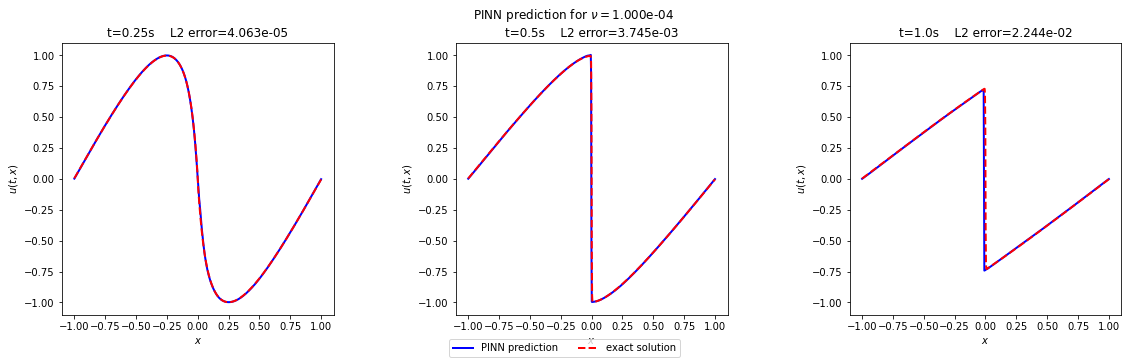

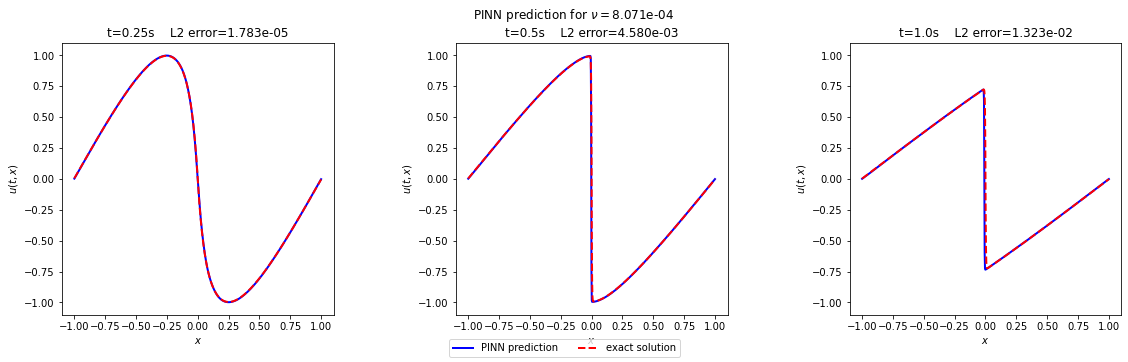

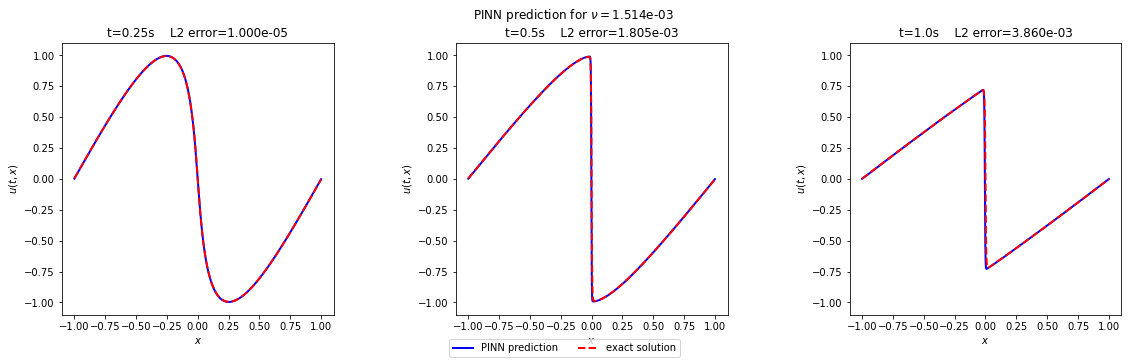

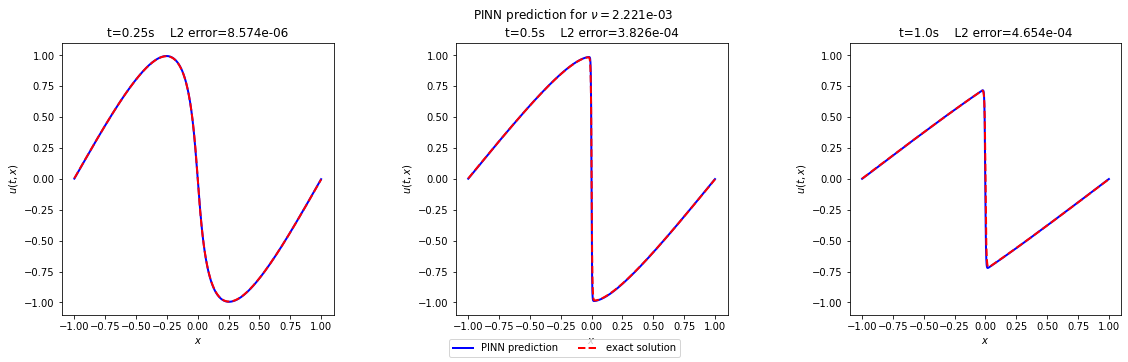

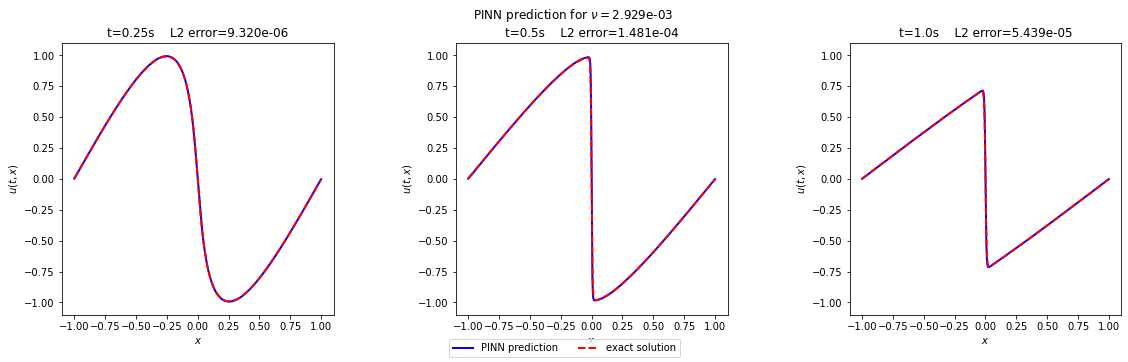

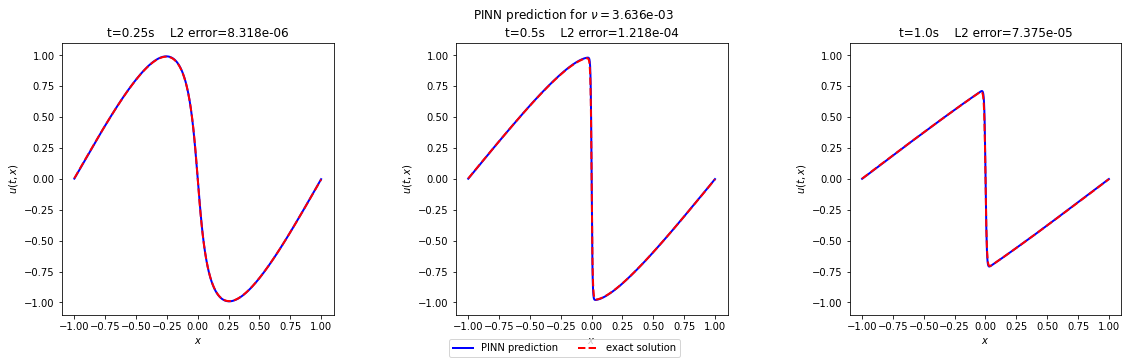

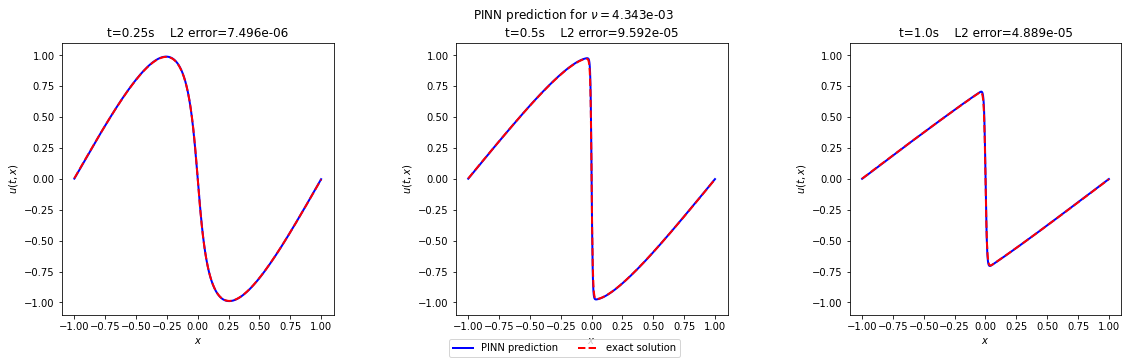

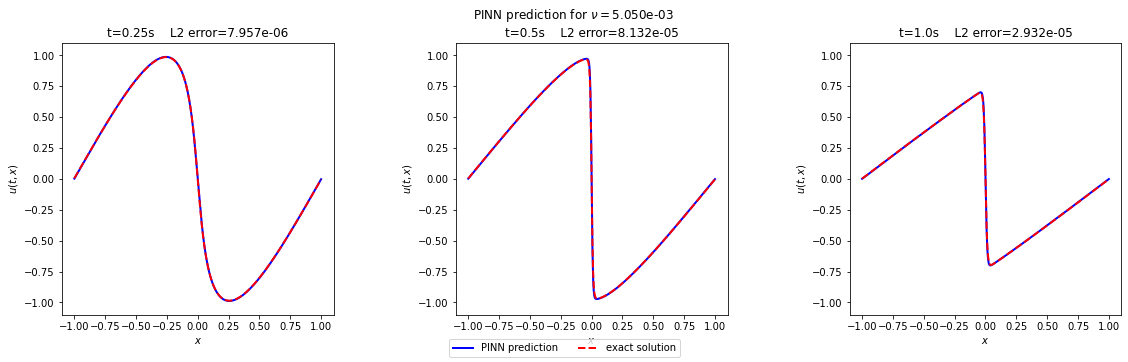

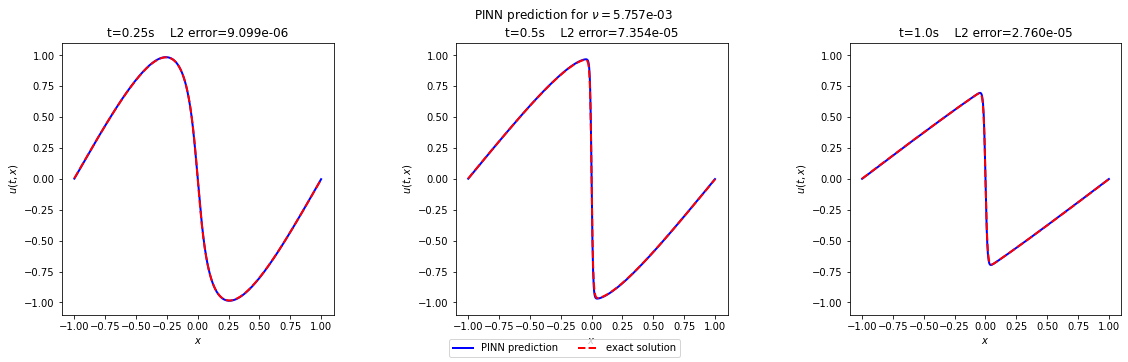

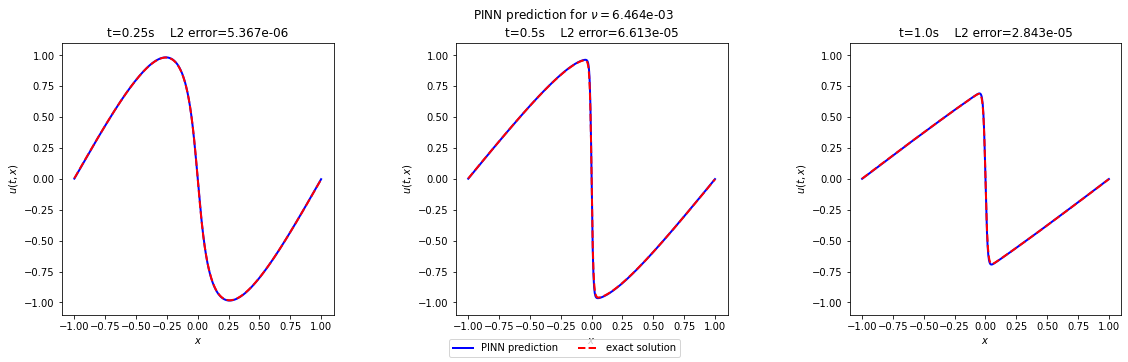

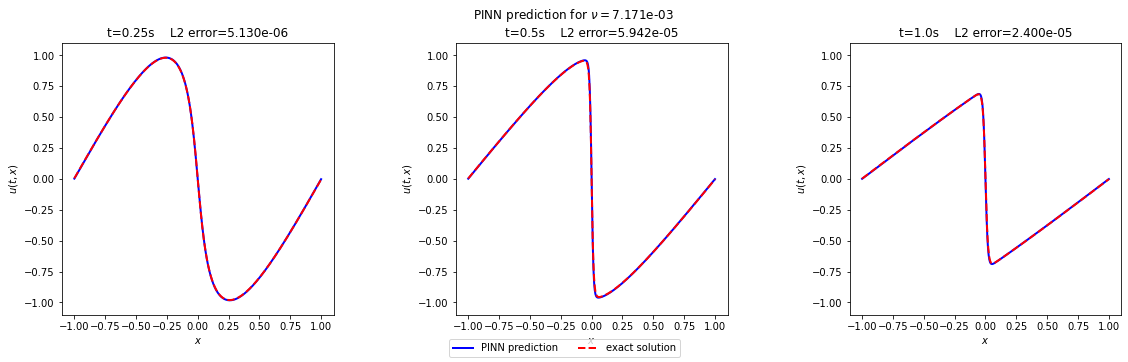

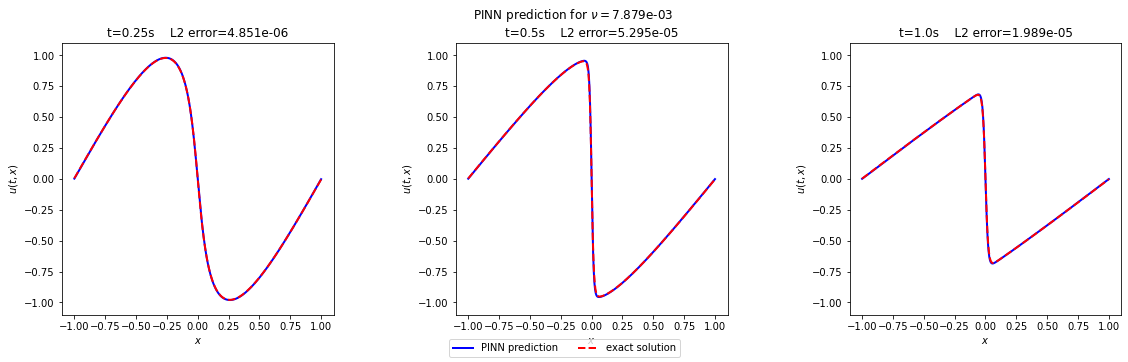

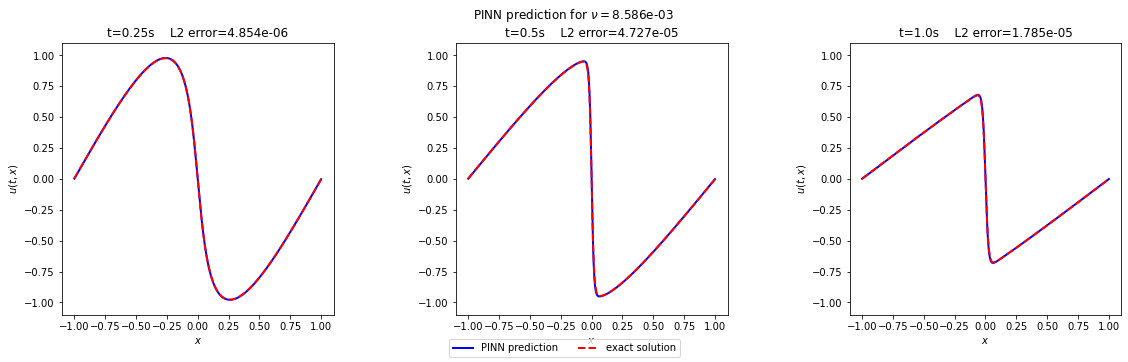

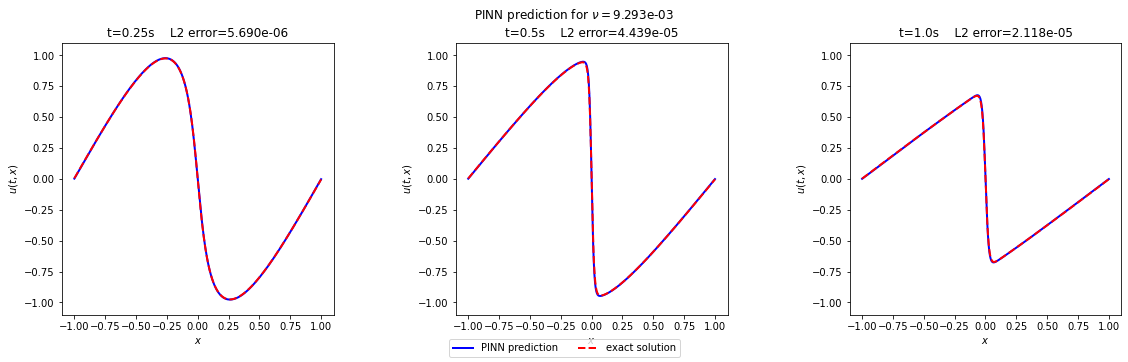

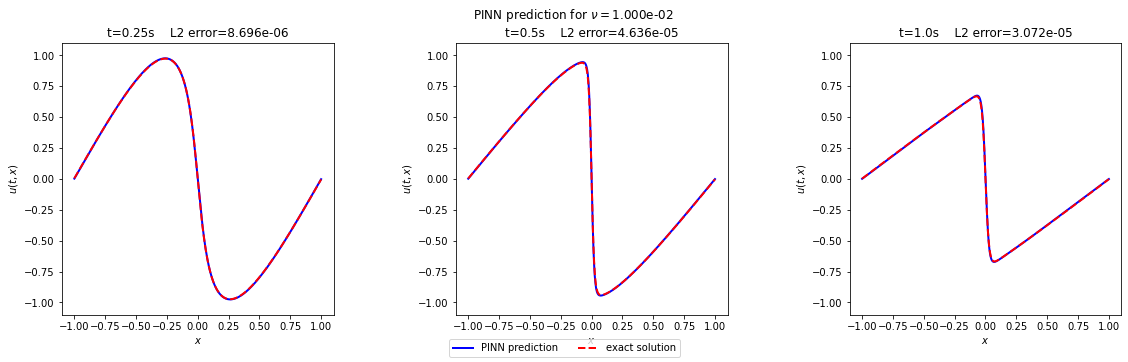

In [16]:
N = 750

for visc in np.linspace(numin, numax, 15):
    
  bg=EDP(N, visc, u_0)
  x = bg.cells[bg.begin:bg.end]

  fig, ax = plt.subplots(1, 3, figsize=(20, 5))

  all_times = [0.25, 0.5, 1.0]
  for i_t, end_time in enumerate(all_times):
    
      bg.init()
      sol=bg.solve(end_time)
      exact_sol = sol[-1]

      # solution en utilisant le PINN
      T, X = np.meshgrid(end_time, x)
      nuspace = visc * np.ones(N)
      Xgrid = np.vstack([T.flatten(),x.flatten(), nuspace.flatten()]).T
      upred = model(tf.cast(Xgrid,DTYPE))
      upred = tf.reshape(upred, (1,N))[0].numpy()

      # affichage
      erreurL2 = (x[-1]-x[0])/N*np.sum((exact_sol-upred)**2)
      title = "t={}s    L2 error={:5.3e}".format(end_time, erreurL2)
      ax[i_t].set_title(title)

      ax[i_t].plot(x, upred, 'b-', linewidth = 2, label="PINN prediction")
      ax[i_t].plot(x, exact_sol, 'r--', linewidth = 2, label="exact solution")

      ax[i_t].set_xlabel('$x$')
      ax[i_t].set_ylabel('$u(t,x)$')    
      ax[i_t].axis('square')
      ax[i_t].set_xlim([-1.1,1.1])
      ax[i_t].set_ylim([-1.1,1.1]);

  handles, labels = ax[-1].get_legend_handles_labels()
  fig.legend(handles, labels, loc='lower center', ncol=4);
  plt.suptitle(r"PINN prediction for $\nu=${:5.3e}".format(visc))

In [17]:
import requests

bot_token = '5169497350:AAHiAyn6D8q9QDoRzTC8HnQU8kYJ-M6xoDg'
bot_chatID = '1061558745'
send_text = 'https://api.telegram.org/bot' + bot_token + '/sendMessage?chat_id=' + bot_chatID + '&parse_mode=Markdown&text=' + 'Les calculs sont finito pipo'

requests.get(send_text)

<Response [200]>